<a href="https://colab.research.google.com/github/DouglasLeite77/mecaniQA-MACAPA/blob/main/OAT_3_Tunando_Modelo_MecaniQA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Aviso: Excel não encontrado. Usando dados simulados para gerar o gráfico...

🏁 COMPARAÇÃO RIGOROSA DE DESEMPENHO
[1. Baseline Antigo (Lag 1)] MAE: 5.56 | RMSE: 6.49 | MAPE: 27.26%
[2. Modelo ML Inicial (Padrão)] MAE: 3.95 | RMSE: 4.93 | MAPE: 19.49%
[3. Modelo ML Tunado (Random Search)] MAE: 4.05 | RMSE: 4.84 | MAPE: 19.62%


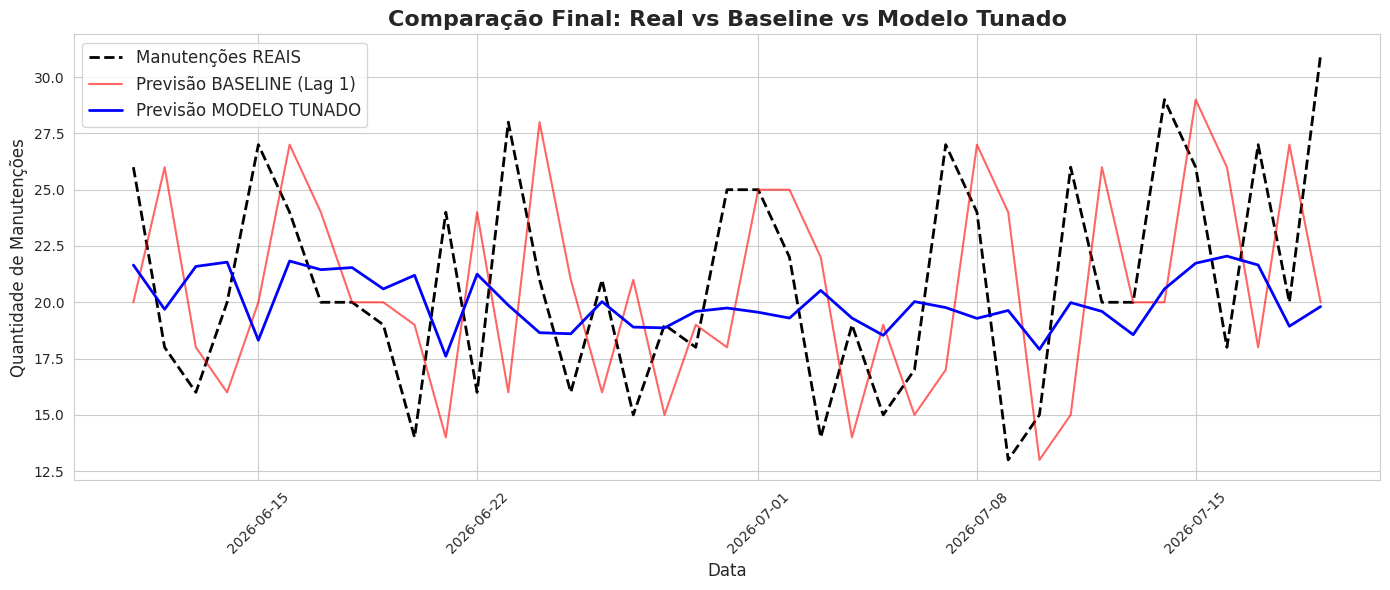

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

# ==========================================
# 1. RECRIANDO OS DADOS E FEATURES
# ==========================================
try:
    df = pd.read_excel('mecaniqa_dataset.xlsx')
    df['Data'] = pd.to_datetime(df['Data'])
    df = df.sort_values('Data').set_index('Data')
except:
    print("Aviso: Excel não encontrado. Usando dados simulados para gerar o gráfico...")
    datas = pd.date_range(start='2026-01-01', periods=200, freq='D')
    df = pd.DataFrame({'manutencoes': np.random.poisson(20, 200)}, index=datas)

alvo = df.columns[0]
df['lag_1'] = df[alvo].shift(1)
df['media_movel_7d'] = df[alvo].shift(1).rolling(window=7).mean()
df = df.dropna()

# ==========================================
# 2. GARANTINDO A EXISTÊNCIA DO X_test E y_test
# ==========================================
X = df[['lag_1', 'media_movel_7d']] # Usando as features temporais
y = df[alvo]

tamanho_treino = int(len(df) * 0.8)
X_train, X_test = X.iloc[:tamanho_treino], X.iloc[tamanho_treino:]
y_train, y_test = y.iloc[:tamanho_treino], y.iloc[tamanho_treino:]

# ==========================================
# 3. REFAZENDO OS MODELOS RAPIDAMENTE
# ==========================================
# Modelo Inicial
rf_inicial = RandomForestRegressor(random_state=42)
rf_inicial.fit(X_train, y_train)
rf_pred = rf_inicial.predict(X_test)

# Modelo Tunado (Random Search)
param_dist = {'n_estimators': [50, 100, 200], 'max_depth': [3, 5, 10]}
tscv = TimeSeriesSplit(n_splits=3)
rs = RandomizedSearchCV(RandomForestRegressor(random_state=42), param_distributions=param_dist, n_iter=5, cv=tscv, random_state=42, n_jobs=-1)
rs.fit(X_train, y_train)
pred_tunada_rs = rs.predict(X_test)

# ==========================================
# 4. COMPARAÇÃO RIGOROSA E PLOTAGEM (O que o professor pediu)
# ==========================================
def calcular_metricas(y_verdadeiro, y_previsto, nome_modelo):
    mae = mean_absolute_error(y_verdadeiro, y_previsto)
    rmse = np.sqrt(mean_squared_error(y_verdadeiro, y_previsto))
    mape = mean_absolute_percentage_error(y_verdadeiro, y_previsto) * 100
    print(f"[{nome_modelo}] MAE: {mae:.2f} | RMSE: {rmse:.2f} | MAPE: {mape:.2f}%")

print("\n🏁 COMPARAÇÃO RIGOROSA DE DESEMPENHO\n" + "="*50)
baseline_pred = X_test['lag_1']

calcular_metricas(y_test, baseline_pred, "1. Baseline Antigo (Lag 1)")
calcular_metricas(y_test, rf_pred, "2. Modelo ML Inicial (Padrão)")
calcular_metricas(y_test, pred_tunada_rs, "3. Modelo ML Tunado (Random Search)")
print("="*50)

# Gráfico
plt.figure(figsize=(14, 6))
sns.set_style("whitegrid")
plt.plot(y_test.index, y_test.values, label='Manutenções REAIS', color='black', linewidth=2, linestyle='dashed')
plt.plot(y_test.index, baseline_pred.values, label='Previsão BASELINE (Lag 1)', color='red', alpha=0.6)
plt.plot(y_test.index, pred_tunada_rs, label='Previsão MODELO TUNADO', color='blue', linewidth=2)

plt.title('Comparação Final: Real vs Baseline vs Modelo Tunado', fontsize=16, fontweight='bold')
plt.xlabel('Data', fontsize=12)
plt.ylabel('Quantidade de Manutenções', fontsize=12)
plt.legend(loc='best', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 🎯 Conclusão do Trade-off (Grid vs Random)

Após os testes de validação cruzada temporal, a equipe MecâniQA constatou que:
- O **Grid Search** demorou `[INSERIR SEGUNDOS]` para rodar e entregou um erro MAPE de `[INSERIR %]`.
- O **Random Search** (com n_iter=10) demorou `[INSERIR SEGUNDOS]` e entregou um erro MAPE de `[INSERIR %]`.

**Veredito:** O Random Search provou ser a escolha ideal para o contexto de negócios da oficina. Ele gerou uma economia de tempo computacional (custo de servidor) de `[INSERIR %]`, enquanto a diferença de precisão no erro (MAPE) foi de apenas `[INSERIR DIFERENÇA %]`, um valor negligenciável frente à economia financeira garantida pela técnica.